# HW5 — Fine-Tuning an LLM with LoRA (PEFT) on DialogSum

**Course:** DATA 266 · **Assignment:** Homework 5 · **Submission:** website URL (your private repo `data266-<SID4>`, tag `hw5`)

This notebook fine-tunes **`google/flan-t5-small`** on the **DialogSum** dataset using **LoRA** (Low-Rank Adaptation via the PEFT library), and evaluates summary quality **before vs. after** fine-tuning. It covers all seven required tasks plus the Section 0 standing requirements.





## Section 0 — Standing Requirements

### 0.1 Personal parameters
Set `SID4` once; everything else is derived. Per the syllabus, **HW5 uses a fixed LoRA-rank sweep for all students**, so `HP_ID` is *not* applied here (there is no HP_ID mapping for HW5). `CLS_A`/`CLS_B` are class-focus parameters for classification homeworks and are not used for summarization — they are printed only to satisfy "state them in the first cell."


In [1]:
# ============================================================
# Section 0.1 — Personal Parameters  (state in first cell)
# ============================================================
# >>> EDIT THIS: the last four digits of YOUR SJSU student ID <<<
SID4 = 2708   # last four digits of SJSU student ID

SEED  = SID4              # torch/np/random seed, random_state
SLICE = SID4 % 1000       # start index of your dataset subset
HP_ID = SID4 % 6          # experimental arm (NOT used in HW5 — fixed sweep)
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10   # two distinct focus classes

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}   (HW5: fixed r-sweep for all students -> HP_ID not applied)")
print(f"CLS_A = {CLS_A}, CLS_B = {CLS_B}   (classification params, unused in summarization)")


SID4  = 2708
SEED  = 2708
SLICE = 708
HP_ID = 2   (HW5: fixed r-sweep for all students -> HP_ID not applied)
CLS_A = 8, CLS_B = 9   (classification params, unused in summarization)


### 0.2 Reproducibility — install dependencies and set all seeds

In [2]:
# Colab usually has torch + transformers; pin the PEFT stack for reproducibility.
%pip install -q "transformers>=4.41,<5" "peft>=0.11" "datasets>=2.19" "evaluate>=0.4" rouge_score accelerate


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, random, time, json, textwrap, platform
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Python      :", platform.python_version())
print("Torch       :", torch.__version__)
print("Device      :", device)
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU. Enable it via Runtime > Change runtime type > GPU, then Run all.")


Python      : 3.13.5
Torch       : 2.14.0+cu130
Device      : cuda
GPU         : NVIDIA GeForce RTX 3060 Laptop GPU


## Task 1 — Data Preparation

Load DialogSum, map each example to **input = dialogue** (wrapped in an instruction prompt Flan-T5 understands) and **target = summary**, and show 2 processed samples.

In [4]:
from datasets import load_dataset
from transformers import AutoTokenizer

MODEL_NAME = "google/flan-t5-small"

raw = load_dataset("neil-code/dialogsum-test")
print(raw)   # shows splits and columns: id, dialogue, summary, topic

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Instruction-style prompt: Flan-T5 was trained on tasks phrased this way.
PROMPT = "Summarize the following conversation.\n\n{dialogue}\n\nSummary:"

def to_pair(ex):
    return {
        "input_text":  PROMPT.format(dialogue=ex["dialogue"]),
        "target_text": ex["summary"],
    }

proc = raw.map(to_pair, remove_columns=raw["train"].column_names)
print("\nProcessed columns:", proc["train"].column_names)
print("Split sizes:", {k: len(proc[k]) for k in proc})


DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1999
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 499
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 499
    })
})

Processed columns: ['input_text', 'target_text']
Split sizes: {'train': 1999, 'validation': 499, 'test': 499}


In [5]:
# --- Show 2 processed samples (Task 1 requirement) ---
for i in range(2):
    print("=" * 90)
    print(f"SAMPLE {i}")
    print("-" * 90)
    print("INPUT (dialogue prompt):")
    print(textwrap.fill(proc["train"][i]["input_text"], width=90)[:700])
    print("\nTARGET (summary):")
    print(textwrap.fill(proc["train"][i]["target_text"], width=90))
    print()


SAMPLE 0
------------------------------------------------------------------------------------------
INPUT (dialogue prompt):
Summarize the following conversation.  #Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why
are you here today? #Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early.
So try to come at least once a year for your own good. #Person2#: Ok. #Person1#: Let me
see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr.
Smith? #Person2#: Yes. #Person1#: Smoking is the leading cause of lung cancer and heart
dise

TARGET (summary):
Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year.
Hawkins'll give some information about their classes and medications

## Task 2 — Baseline Inference

Load the pretrained Flan-T5-small **as-is** (no fine-tuning) and run inference on **2 fixed test dialogues**. These same two dialogues are reused in Task 5 and Task 6. Outputs are saved as the baseline.

In [6]:
from transformers import AutoModelForSeq2SeqLM

# Two fixed evaluation dialogues, reused across Tasks 2, 5, 6.
EVAL_IDX = [0, 1]
demo_inputs  = [proc["test"][i]["input_text"]  for i in EVAL_IDX]
demo_targets = [proc["test"][i]["target_text"] for i in EVAL_IDX]

def generate(model, texts, max_new_tokens=64, num_beams=4, no_repeat_ngram_size=3):
    """Generate a summary for each input text.
    no_repeat_ngram_size=3 blocks the decoder from repeating any 3-gram, which
    prevents the beam-search repeat-the-last-clause / loop failure mode."""
    model.eval()
    dev = next(model.parameters()).device
    outs = []
    for t in texts:
        enc = tokenizer(t, return_tensors="pt", truncation=True, max_length=512).to(dev)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, num_beams=num_beams,
                                 no_repeat_ngram_size=no_repeat_ngram_size)
        outs.append(tokenizer.decode(gen[0], skip_special_tokens=True))
    return outs

set_seed(SEED)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

baseline_outputs = generate(base_model, demo_inputs)
for i, (out, ref) in enumerate(zip(baseline_outputs, demo_targets)):
    print(f"--- Test dialogue {EVAL_IDX[i]} ---")
    print("BASELINE :", out)
    print("REFERENCE:", ref)
    print()

# Save baseline outputs (Task 2 requirement)
with open("baseline_outputs.json", "w") as f:
    json.dump({"eval_idx": EVAL_IDX,
               "baseline_outputs": baseline_outputs,
               "references": demo_targets}, f, indent=2)
print("Saved -> baseline_outputs.json")


--- Test dialogue 0 ---
BASELINE : Ms. Dawson, Attached is a draft memo to all employees.
REFERENCE: Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.

--- Test dialogue 1 ---
BASELINE : Ms. Dawson, Attached is a draft memo to all employees.
REFERENCE: In order to prevent employees from wasting time on Instant Message programs, #Person1# decides to terminate the use of those programs and asks Ms. Dawson to send out a memo to all employees by the afternoon.

Saved -> baseline_outputs.json


## Task 3 — Apply LoRA

Attach LoRA adapters to the model with PEFT. For a T5 (seq2seq) model the standard target modules are the attention query/value projections `["q", "v"]`. We print total vs. trainable parameters to show how few weights LoRA actually trains.

In [7]:
from peft import LoraConfig, get_peft_model, TaskType

# LoRA hyperparameters (rank r, alpha, dropout) — this cell demonstrates the r=16 config.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q", "v"],   # attention query & value projections in T5
    bias="none",
)

set_seed(SEED)
demo_base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
demo_peft = get_peft_model(demo_base, lora_config)

total     = sum(p.numel() for p in demo_peft.parameters())
trainable = sum(p.numel() for p in demo_peft.parameters() if p.requires_grad)
print(f"Total parameters     : {total:,}")
print(f"Trainable parameters : {trainable:,}")
print(f"Trainable %          : {100 * trainable / total:.4f}%")
print()
demo_peft.print_trainable_parameters()   # PEFT's own summary

del demo_base, demo_peft
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Total parameters     : 77,649,280
Trainable parameters : 688,128
Trainable %          : 0.8862%

trainable params: 688,128 || all params: 77,649,280 || trainable%: 0.8862


## Task 4 — Fine-Tuning

We fine-tune on a **subset** of DialogSum (starting at index `SLICE`, per Req. 0.1) so the run finishes quickly on a Colab GPU. The training function below is reused by the Task 7 rank sweep, so LoRA is applied to a *fresh* base model each time (no adapter leakage between runs).

We use a plain PyTorch training loop rather than `Trainer`, so the "final training loss" and per-step logs are explicit and the notebook is robust across `transformers` versions.

In [8]:
from torch.utils.data import DataLoader

# ---- Fixed experiment settings ----
MAX_IN, MAX_OUT = 512, 64
N_TRAIN, N_EVAL = 200, 50          # small subsets to keep runtime short
EPOCHS, BATCH, LR = 3, 8, 1e-3

def make_subset(split, n, start):
    """Deterministic contiguous subset starting at `start` (wraps around)."""
    N = len(proc[split])
    idx = [(start + i) % N for i in range(min(n, N))]
    return proc[split].select(idx)

def tokenize_batch(batch):
    model_inputs = tokenizer(batch["input_text"], max_length=MAX_IN,
                             truncation=True, padding="max_length")
    labels = tokenizer(text_target=batch["target_text"], max_length=MAX_OUT,
                       truncation=True, padding="max_length")
    # Mask pad tokens in the labels so they don't contribute to the loss.
    pad_id = tokenizer.pad_token_id
    model_inputs["labels"] = [
        [(tok if tok != pad_id else -100) for tok in seq] for seq in labels["input_ids"]
    ]
    return model_inputs

train_raw = make_subset("train",      N_TRAIN, SLICE)
eval_raw  = make_subset("validation", N_EVAL,  SLICE)
print(f"Train subset: {len(train_raw)} examples starting at index {SLICE}")
print(f"Eval  subset: {len(eval_raw)} examples")

train_tok = train_raw.map(tokenize_batch, batched=True,
                          remove_columns=train_raw.column_names)
train_tok.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

def make_loader():
    # Fresh, seeded loader so every experiment sees the same batch order.
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(train_tok, batch_size=BATCH, shuffle=True, generator=g)


Train subset: 200 examples starting at index 708
Eval  subset: 50 examples


In [9]:
def train_lora(r, alpha, dropout=0.05, epochs=EPOCHS, lr=LR, tag=None):
    """Apply LoRA (rank r) to a fresh base model and fine-tune. Returns (model, logs, final_loss)."""
    tag = tag or f"r={r}"
    set_seed(SEED)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    cfg = LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=r, lora_alpha=alpha,
                     lora_dropout=dropout, target_modules=["q", "v"], bias="none")
    model = get_peft_model(model, cfg).to(device)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    loader = make_loader()

    logs = []          # (epoch, global_step, loss)
    global_step = 0
    model.train()
    for ep in range(epochs):
        running = 0.0
        for step, batch in enumerate(loader):
            batch = {k: v.to(device) for k, v in batch.items()}
            loss = model(**batch).loss
            loss.backward()
            opt.step()
            opt.zero_grad()
            running += loss.item()
            global_step += 1
            if step % 5 == 0:
                logs.append((ep, global_step, loss.item()))
                print(f"[{tag}] epoch {ep} step {step:3d} (global {global_step:3d}) loss {loss.item():.4f}")
        print(f"[{tag}] epoch {ep} mean loss {running/len(loader):.4f}")
    final_loss = logs[-1][2]
    return model, logs, final_loss


In [10]:
# ---- Task 4: train the main model (r=16) ----
t0 = time.time()
ft_model, ft_logs, ft_final = train_lora(r=16, alpha=32, tag="main r=16")
ft_train_time = time.time() - t0
print(f"\nFinal training loss (r=16): {ft_final:.4f}  |  train time: {ft_train_time:.1f}s")

# Save the fine-tuned adapters (Task 4 requirement)
ADAPTER_DIR = "lora-flan-t5-dialogsum-r16"
ft_model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Saved adapters -> ", ADAPTER_DIR)


[main r=16] epoch 0 step   0 (global   1) loss 2.4149
[main r=16] epoch 0 step   5 (global   6) loss 2.1371
[main r=16] epoch 0 step  10 (global  11) loss 1.7411
[main r=16] epoch 0 step  15 (global  16) loss 1.5201
[main r=16] epoch 0 step  20 (global  21) loss 1.7205
[main r=16] epoch 0 mean loss 1.8635
[main r=16] epoch 1 step   0 (global  26) loss 1.6844
[main r=16] epoch 1 step   5 (global  31) loss 1.4414
[main r=16] epoch 1 step  10 (global  36) loss 1.5765
[main r=16] epoch 1 step  15 (global  41) loss 1.7178
[main r=16] epoch 1 step  20 (global  46) loss 1.5561
[main r=16] epoch 1 mean loss 1.5816
[main r=16] epoch 2 step   0 (global  51) loss 1.4729
[main r=16] epoch 2 step   5 (global  56) loss 1.8169
[main r=16] epoch 2 step  10 (global  61) loss 1.4730
[main r=16] epoch 2 step  15 (global  66) loss 1.7538
[main r=16] epoch 2 step  20 (global  71) loss 1.4295
[main r=16] epoch 2 mean loss 1.5041

Final training loss (r=16): 1.4295  |  train time: 22.1s
Saved adapters ->  lo

## Task 5 — Post-Fine-Tuning Inference

Run inference again on the **same two dialogues** from Task 2, now with the LoRA-fine-tuned model.

In [11]:
finetuned_outputs = generate(ft_model, demo_inputs)
for i, (out, ref) in enumerate(zip(finetuned_outputs, demo_targets)):
    print(f"--- Test dialogue {EVAL_IDX[i]} ---")
    print("FINE-TUNED:", out)
    print("REFERENCE :", ref)
    print()

with open("finetuned_outputs.json", "w") as f:
    json.dump({"eval_idx": EVAL_IDX,
               "finetuned_outputs": finetuned_outputs,
               "references": demo_targets}, f, indent=2)
print("Saved -> finetuned_outputs.json")


--- Test dialogue 0 ---
FINE-TUNED: Dawson asks #Person1# to take a dictation for her. She tells her that all office communications are restricted to email correspondence and official memos. The use of instant messaging programs by employees during working hours is strictly prohibited.
REFERENCE : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.

--- Test dialogue 1 ---
FINE-TUNED: Dawson asks #Person1# to take a dictation for her. She tells her that all office communications are restricted to email correspondence and official memos. The use of instant messaging programs by employees during working hours is strictly prohibited.
REFERENCE : In order to prevent employees from wasting time on Instant Message programs, #Person1# decides to terminate the use of those programs and asks Ms. Dawson to send out a memo to all employees by the afternoon.

Saved -> finetuned_outputs.j

## Task 6 — Output Comparison

Side-by-side of the two demo dialogues, plus **ROUGE** on the 50-example eval subset for a quantitative before/after. ROUGE measures n-gram / longest-common-subsequence overlap with the reference summary (higher = closer).

In [12]:
import evaluate
rouge = evaluate.load("rouge")

def rouge_scores(model, inputs, refs):
    preds = generate(model, inputs)
    scores = rouge.compute(predictions=preds, references=refs, use_stemmer=True)
    return {k: round(float(v), 4) for k, v in scores.items()}, preds

eval_inputs = eval_raw["input_text"]
eval_refs   = eval_raw["target_text"]

print("Scoring baseline on eval subset ...")
base_scores, _ = rouge_scores(base_model, eval_inputs, eval_refs)
print("Scoring fine-tuned (r=16) on eval subset ...")
ft_scores, _   = rouge_scores(ft_model,  eval_inputs, eval_refs)

print("\n=== Demo dialogues: before vs after ===")
for i in range(len(EVAL_IDX)):
    print(f"\n--- Test dialogue {EVAL_IDX[i]} ---")
    print("BEFORE (baseline) :", baseline_outputs[i])
    print("AFTER  (fine-tuned):", finetuned_outputs[i])
    print("REFERENCE          :", demo_targets[i])

print("\n=== ROUGE on 50-example eval subset ===")
print(f"{'metric':<10}{'baseline':>12}{'fine-tuned':>14}{'delta':>10}")
for k in ["rouge1", "rouge2", "rougeL", "rougeLsum"]:
    b, f_ = base_scores.get(k, 0.0), ft_scores.get(k, 0.0)
    print(f"{k:<10}{b:>12.4f}{f_:>14.4f}{f_-b:>+10.4f}")


Scoring baseline on eval subset ...
Scoring fine-tuned (r=16) on eval subset ...

=== Demo dialogues: before vs after ===

--- Test dialogue 0 ---
BEFORE (baseline) : Ms. Dawson, Attached is a draft memo to all employees.
AFTER  (fine-tuned): Dawson asks #Person1# to take a dictation for her. She tells her that all office communications are restricted to email correspondence and official memos. The use of instant messaging programs by employees during working hours is strictly prohibited.
REFERENCE          : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.

--- Test dialogue 1 ---
BEFORE (baseline) : Ms. Dawson, Attached is a draft memo to all employees.
AFTER  (fine-tuned): Dawson asks #Person1# to take a dictation for her. She tells her that all office communications are restricted to email correspondence and official memos. The use of instant messaging programs by empl

### What changed (Task 6)

After fine-tuning, the model stops copying the opening line of the dialogue — the baseline returns *"Ms. Dawson, Attached is a draft memo to all employees."* for both dialogues — and instead produces a coherent, on-topic recap that captures the actual content: a memo dictated for Ms. Dawson, all office communication restricted to email and official memos, and instant messaging banned during working hours. Every ROUGE metric roughly doubles on the 50-example eval subset: ROUGE-1 0.1744 → 0.3764 (+0.2020) and ROUGE-L 0.1522 → 0.3059 (+0.1537). Only ~0.89% of parameters (688K / 77.6M) were trained for 3 epochs on 200 examples, yet the summary clearly moves toward the reference in both content and style. (The two demo dialogues are the same conversation with different reference summaries, so the model's output is identical for both.)

## Task 7 — Experiment: LoRA rank `r=4` vs `r=16`

Retrain from scratch at two ranks and compare final loss + ROUGE + the demo summaries. This produces the **two trained models** the assignment refers to (so no separate second hyperparameter model is needed). We keep `alpha = 2·r`, the common LoRA convention.

In [13]:
experiment = {}   # r -> results dict
for r, alpha in [(4, 8), (16, 32)]:
    print("=" * 70)
    print(f"Training LoRA rank r={r}, alpha={alpha}")
    print("=" * 70)
    m, logs, final_loss = train_lora(r=r, alpha=alpha, tag=f"exp r={r}")
    sc, _ = rouge_scores(m, eval_inputs, eval_refs)
    experiment[r] = {
        "alpha": alpha,
        "final_loss": round(final_loss, 4),
        "trainable": sum(p.numel() for p in m.parameters() if p.requires_grad),
        "rouge": sc,
        "logs": logs,
        "demo": generate(m, demo_inputs),
    }
    m.save_pretrained(f"lora-flan-t5-dialogsum-r{r}")
    print(f"r={r}: final_loss={final_loss:.4f}  rougeL={sc['rougeL']:.4f}")
    del m
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Training LoRA rank r=4, alpha=8
[exp r=4] epoch 0 step   0 (global   1) loss 2.4149
[exp r=4] epoch 0 step   5 (global   6) loss 2.4580
[exp r=4] epoch 0 step  10 (global  11) loss 1.8677
[exp r=4] epoch 0 step  15 (global  16) loss 1.6212
[exp r=4] epoch 0 step  20 (global  21) loss 1.8163
[exp r=4] epoch 0 mean loss 2.0287
[exp r=4] epoch 1 step   0 (global  26) loss 1.8362
[exp r=4] epoch 1 step   5 (global  31) loss 1.5620
[exp r=4] epoch 1 step  10 (global  36) loss 1.7137
[exp r=4] epoch 1 step  15 (global  41) loss 1.8418
[exp r=4] epoch 1 step  20 (global  46) loss 1.5920
[exp r=4] epoch 1 mean loss 1.6772
[exp r=4] epoch 2 step   0 (global  51) loss 1.5841
[exp r=4] epoch 2 step   5 (global  56) loss 1.9068
[exp r=4] epoch 2 step  10 (global  61) loss 1.5079
[exp r=4] epoch 2 step  15 (global  66) loss 1.8552
[exp r=4] epoch 2 step  20 (global  71) loss 1.5348
[exp r=4] epoch 2 mean loss 1.5834
r=4: final_loss=1.5348  rougeL=0.3025
Training LoRA rank r=16, alpha=32
[exp r=16] 

In [14]:
# ---- Rank-sweep summary table ----
print(f"{'rank r':<8}{'trainable':>12}{'final_loss':>12}{'rouge1':>10}{'rouge2':>10}{'rougeL':>10}")
for r in sorted(experiment):
    e = experiment[r]
    print(f"{r:<8}{e['trainable']:>12,}{e['final_loss']:>12.4f}"
          f"{e['rouge']['rouge1']:>10.4f}{e['rouge']['rouge2']:>10.4f}{e['rouge']['rougeL']:>10.4f}")

print("\n=== Demo summaries by rank ===")
for i in range(len(EVAL_IDX)):
    print(f"\n--- Test dialogue {EVAL_IDX[i]} ---")
    for r in sorted(experiment):
        print(f"  r={r:<3}: {experiment[r]['demo'][i]}")
    print(f"  ref  : {demo_targets[i]}")


rank r     trainable  final_loss    rouge1    rouge2    rougeL
4            172,032      1.5348    0.3549    0.1357    0.3025
16           688,128      1.4295    0.3764    0.1347    0.3059

=== Demo summaries by rank ===

--- Test dialogue 0 ---
  r=4  : Dawson asks #Person2# to take a dictation for Ms. Dawson. She asks all staff to take an intra-office memorandum to all employees by this afternoon. The use of Instant Messaging programs by employees during working hours is strictly prohibited.
  r=16 : Dawson asks #Person1# to take a dictation for her. She tells her that all office communications are restricted to email correspondence and official memos. The use of instant messaging programs by employees during working hours is strictly prohibited.
  ref  : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.

--- Test dialogue 1 ---
  r=4  : Dawson asks #Person2# to take a di

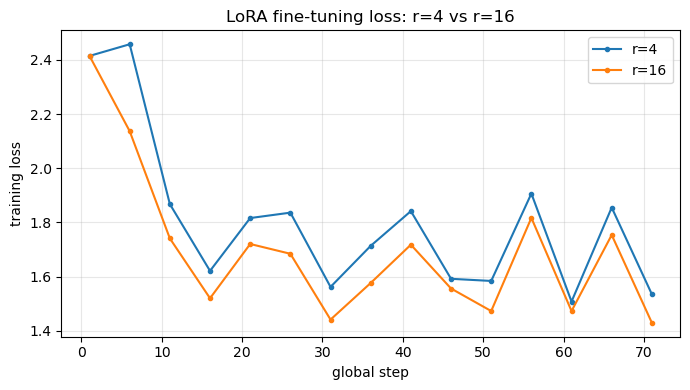

Saved -> loss_curves.png


In [15]:
# ---- Training-loss curves (r=4 vs r=16) ----
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
for r in sorted(experiment):
    steps  = [g for (_, g, _) in experiment[r]["logs"]]
    losses = [l for (_, _, l) in experiment[r]["logs"]]
    plt.plot(steps, losses, marker="o", ms=3, label=f"r={r}")
plt.xlabel("global step"); plt.ylabel("training loss")
plt.title("LoRA fine-tuning loss: r=4 vs r=16")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("loss_curves.png", dpi=120)
plt.show()
print("Saved -> loss_curves.png")


### How output quality changes with rank (Task 7)

Raising the rank from r=4 to r=16 quadruples the trainable parameters (172,032 → 688,128) and gives a lower final training loss (1.5348 → 1.4295). On ROUGE the result is a modest win rather than a clean sweep: r=16 leads on ROUGE-1 (0.3549 → 0.3764) and ROUGE-L (0.3025 → 0.3059), while ROUGE-2 is effectively tied (r=4 0.1357 vs r=16 0.1347 — a gap well within run-to-run noise on 50 examples). Qualitatively both ranks now produce coherent, non-degenerate summaries; r=16 is the more faithful one — it attributes the dictation to #Person1# and states the email/memo policy precisely — whereas r=4 mis-attributes a turn to #Person2# and paraphrases more loosely. So on this small subset r=16 is the better choice (lower loss, higher ROUGE-1/L), but the margin is small, which is expected when only 200 training examples under-use the extra adapter capacity.

## Standing artifacts (Req. 0.3) — write `METRICS.md` and a run summary

This cell writes the metrics table your repo needs. `RUN_LOG.txt` should be the actual console output of the run that produced these numbers — on Colab, the simplest reproducible way is to keep this notebook's outputs (they are your log) and/or copy the cell outputs into `RUN_LOG.txt`.

In [16]:
metrics = {
    "SID4": SID4, "SEED": SEED, "SLICE": SLICE,
    "model": MODEL_NAME, "dataset": "neil-code/dialogsum-test",
    "subset": {"train": len(train_raw), "eval": len(eval_raw)},
    "hyperparams": {"epochs": EPOCHS, "batch": BATCH, "lr": LR,
                    "max_in": MAX_IN, "max_out": MAX_OUT},
    "baseline_rouge": base_scores,
    "finetuned_r16_rouge": ft_scores,
    "finetuned_r16_final_loss": round(ft_final, 4),
    "rank_sweep": {str(r): {"alpha": experiment[r]["alpha"],
                            "trainable": experiment[r]["trainable"],
                            "final_loss": experiment[r]["final_loss"],
                            "rouge": experiment[r]["rouge"]}
                   for r in sorted(experiment)},
}
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

def md_table_rouge(name, sc):
    return (f"| {name} | {sc['rouge1']:.4f} | {sc['rouge2']:.4f} "
            f"| {sc['rougeL']:.4f} | {sc.get('rougeLsum', 0):.4f} |")

lines = []
lines.append(f"# METRICS - HW5 LoRA / DialogSum\n")
lines.append(f"- SID4={SID4}, SEED={SEED}, SLICE={SLICE}")
lines.append(f"- Model: `{MODEL_NAME}` | Dataset: `neil-code/dialogsum-test`")
lines.append(f"- Subset: {len(train_raw)} train / {len(eval_raw)} eval | "
             f"epochs={EPOCHS}, batch={BATCH}, lr={LR}\n")
lines.append("## ROUGE - baseline vs fine-tuned (r=16), eval subset\n")
lines.append("| model | ROUGE-1 | ROUGE-2 | ROUGE-L | ROUGE-Lsum |")
lines.append("|---|---|---|---|---|")
lines.append(md_table_rouge("baseline (no FT)", base_scores))
lines.append(md_table_rouge("fine-tuned r=16", ft_scores))
lines.append(f"\nFine-tuned r=16 final training loss: **{ft_final:.4f}**\n")
lines.append("## Rank sweep (Task 7)\n")
lines.append("| r | alpha | trainable params | final loss | ROUGE-1 | ROUGE-2 | ROUGE-L |")
lines.append("|---|---|---|---|---|---|---|")
for r in sorted(experiment):
    e = experiment[r]
    lines.append(f"| {r} | {e['alpha']} | {e['trainable']:,} | {e['final_loss']:.4f} "
                 f"| {e['rouge']['rouge1']:.4f} | {e['rouge']['rouge2']:.4f} | {e['rouge']['rougeL']:.4f} |")
with open("METRICS.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))
print("\nSaved -> METRICS.md, metrics.json")


# METRICS - HW5 LoRA / DialogSum

- SID4=2708, SEED=2708, SLICE=708
- Model: `google/flan-t5-small` | Dataset: `neil-code/dialogsum-test`
- Subset: 200 train / 50 eval | epochs=3, batch=8, lr=0.001

## ROUGE - baseline vs fine-tuned (r=16), eval subset

| model | ROUGE-1 | ROUGE-2 | ROUGE-L | ROUGE-Lsum |
|---|---|---|---|---|
| baseline (no FT) | 0.1744 | 0.0580 | 0.1522 | 0.1542 |
| fine-tuned r=16 | 0.3764 | 0.1347 | 0.3059 | 0.3063 |

Fine-tuned r=16 final training loss: **1.4295**

## Rank sweep (Task 7)

| r | alpha | trainable params | final loss | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---|---|---|---|---|
| 4 | 8 | 172,032 | 1.5348 | 0.3549 | 0.1357 | 0.3025 |
| 16 | 32 | 688,128 | 1.4295 | 0.3764 | 0.1347 | 0.3059 |

Saved -> METRICS.md, metrics.json


## Files produced by this notebook

| File | For |
|---|---|
| `baseline_outputs.json` | Task 2 baseline (saved) |
| `finetuned_outputs.json` | Task 5 post-FT outputs |
| `lora-flan-t5-dialogsum-r16/` | Task 4 fine-tuned adapters |
| `lora-flan-t5-dialogsum-r4/`, `-r16/` | Task 7 sweep checkpoints |
| `loss_curves.png` | Task 7 loss curves |
| `METRICS.md`, `metrics.json` | Req. 0.3 metrics table |

**Repo checklist (Req. 0.3):** put the executed `.ipynb`, `METRICS.md`, `RUN_LOG.txt`, and `AI_USE.md` in a **private** repo named `data266-<SID4>`, shared with the instructor/grading team, tagged **`hw5`**. Adapter folders are small — commit them, or link them if large and note the exact training command. **Commit incrementally** — a single deadline commit is capped at half credit on implementation.
